# Waste Classification – Transfer Learning (TrashNet, 6 classes)
Modified and finalized project based on `aniass/Waste-Classification / waste_transfer_learning.ipynb`.
Compatible with **Google Colab** (GPU/CPU) and local environments (Windows/Linux/macOS).

## Project Overview & Improvements
| # | Original Repo / Initial State | This Notebook | Engineering Rationale |
|---|---|---|---|
| 1 | Dataset: 2 classes (binary) | **TrashNet (6 classes, 2,527 images)** | Realistic multi-class waste benchmark (cardboard, glass, metal, paper, plastic, trash) |
| 2 | Bash `!unzip` & Google Drive path | **Cross-platform `zipfile` extraction** | Eliminates `FileNotFoundError` on Windows and non-Colab setups; cleans macOS metadata |
| 3 | `binary_crossentropy` & sigmoid | **`sparse_categorical_crossentropy` + softmax** | Mathematically correct for 6 mutually exclusive classes |
| 4 | Rescaling `1./255` | **`mobilenet_v2.preprocess_input`** | MobileNetV2 expects normalized inputs in the range `[-1, 1]` |
| 5 | Image size 128x128 | **224x224** | Native resolution for pretrained MobileNetV2 weights |
| 6 | `Flatten()` + Dense(32/64) | **`GlobalAveragePooling2D()` + Dropout(0.3)** | Prevents severe overfitting and reduces parameter footprint |
| 7 | `vertical_flip=True` | **Horizontal flip, rotation 0.1, zoom 0.2** | Preserves upright object orientation for realistic garbage items |
| 8 | Non-deterministic test split | **Deterministic 70% Train / 15% Val / 15% Test with `.cache()`** | Prevents test set shuffling and label misalignment across multiple evaluation passes |
| 9 | Reused callback instances | **Independent callbacks per stage** | Prevents Stage 2 from inheriting Stage 1 step counts and best loss values |
| 10| Stage 1 & Stage 2 Training | **Stage 1 (Frozen Base) + Stage 2 (Fine-tune top 40 layers)** | Maximizes transfer learning adaptation without catastrophic forgetting |
| 11| Accuracy only | **Classification Report, Confusion Matrix Heatmap, 8 Misclassified Samples** | In-depth error diagnosis for class confusion |
| 12| Blocking Gradio demo | **Robust Gradio Web Interface** | Top-3 class predictions with null-safety and non-blocking execution |


## 1. Setup and Dataset Extraction

In [1]:
import os
import zipfile
import shutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
import gradio as gr

print("TensorFlow Version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

# Dataset extraction using standard cross-platform zipfile
data_dir = "trashnet_data/dataset-resized"
zip_path = "dataset-resized.zip"

if not os.path.exists(data_dir):
    if not os.path.exists(zip_path) and os.path.exists("trashnet/data/dataset-resized.zip"):
        zip_path = "trashnet/data/dataset-resized.zip"
    
    if os.path.exists(zip_path):
        print(f"Extracting {zip_path} into trashnet_data...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall("trashnet_data")
    else:
        print("Cloning TrashNet dataset from GitHub repository...")
        os.system("git clone -q --depth 1 https://github.com/garythung/trashnet")
        with zipfile.ZipFile("trashnet/data/dataset-resized.zip", 'r') as zip_ref:
            zip_ref.extractall("trashnet_data")

    # Clean macOS metadata artifacts (__MACOSX, .DS_Store, ._*)
    for root, dirs, files in os.walk("trashnet_data"):
        for f in files:
            if f.startswith("._") or f == ".DS_Store":
                try: os.remove(os.path.join(root, f))
                except OSError: pass
        if "__MACOSX" in dirs:
            shutil.rmtree(os.path.join(root, "__MACOSX"), ignore_errors=True)

print("Dataset ready at:", data_dir)


TensorFlow Version: 2.21.0
Available GPUs: []
Dataset ready at: trashnet_data/dataset-resized


## 2. Verify Class Directory Structure and Sample Counts

In [2]:
classes = [c for c in sorted(os.listdir(data_dir)) if os.path.isdir(os.path.join(data_dir, c))]
print(f"Detected {len(classes)} classes: {classes}\n")

total_images = 0
for c in classes:
    class_folder = os.path.join(data_dir, c)
    count = len([f for f in os.listdir(class_folder) if not f.startswith(".")])
    total_images += count
    print(f"  - {c:10s}: {count:4d} images")

print(f"\nTotal images: {total_images}")


Detected 6 classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

  - cardboard :  403 images
  - glass     :  501 images
  - metal     :  410 images
  - paper     :  594 images
  - plastic   :  482 images
  - trash     :  137 images

Total images: 2527


## 3. Data Loading: 70% Train / 15% Validation / 15% Test Split

In [3]:
IMG = (224, 224)
BS = 32
SEED = 42

# 70% Training split
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3,
    subset="training",
    seed=SEED,
    image_size=IMG,
    batch_size=BS
)

# 30% Remaining split
rest_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3,
    subset="validation",
    seed=SEED,
    image_size=IMG,
    batch_size=BS
)

class_names = train_ds.class_names
num_classes = len(class_names)
n_rest = tf.data.experimental.cardinality(rest_ds).numpy()

# Partition 30% into 15% validation and 15% test
val_ds  = rest_ds.take(n_rest // 2)
test_ds = rest_ds.skip(n_rest // 2)

# Cache datasets in memory to ensure deterministic sample ordering across all evaluation loops
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

print(f"Classes ({num_classes}): {class_names}")
print(f"Batch distribution -> Train: {tf.data.experimental.cardinality(train_ds).numpy()}, "
      f"Val: {tf.data.experimental.cardinality(val_ds).numpy()}, "
      f"Test: {tf.data.experimental.cardinality(test_ds).numpy()}")


Found 2527 files belonging to 6 classes.
Using 1769 files for training.
Found 2527 files belonging to 6 classes.
Using 758 files for validation.
Classes (6): ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Batch distribution -> Train: 56, Val: 12, Test: 12


### Class Distribution (Training Set)

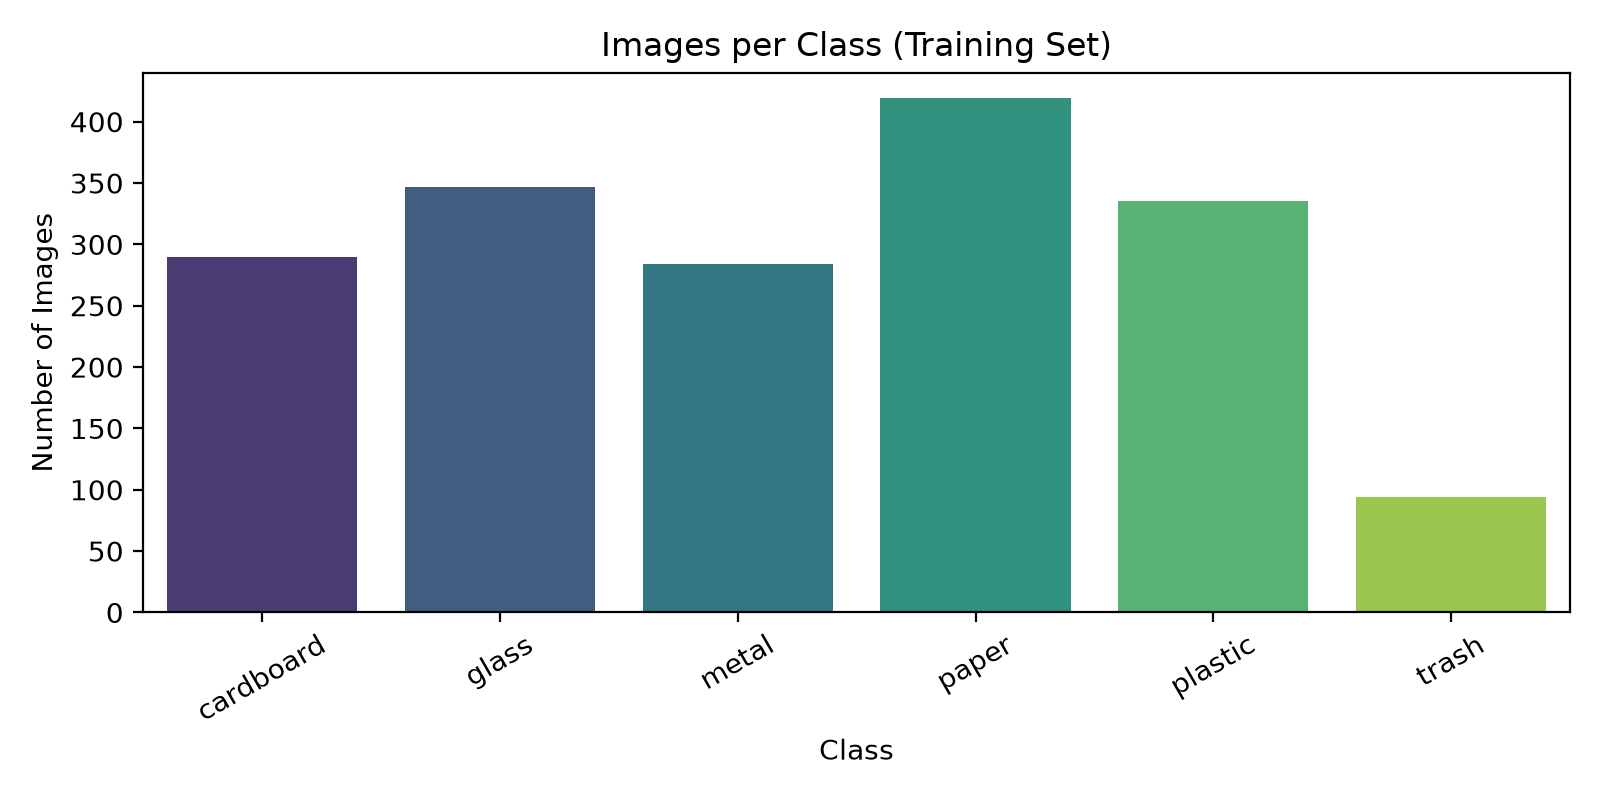

In [4]:
counts = np.zeros(num_classes, dtype=int)
for _, y in train_ds.unbatch():
    counts[int(y)] += 1

plt.figure(figsize=(8, 4))
bars = plt.bar(class_names, counts, color=sns.color_palette("muted", num_classes))
plt.title("TrashNet Class Distribution (Training Set)", fontsize=13, fontweight='bold')
plt.xlabel("Waste Category", fontsize=11)
plt.ylabel("Number of Images", fontsize=11)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 10, f"{int(yval)}", ha='center', va='bottom', fontsize=10)
plt.ylim(0, max(counts) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Sample Dataset Images

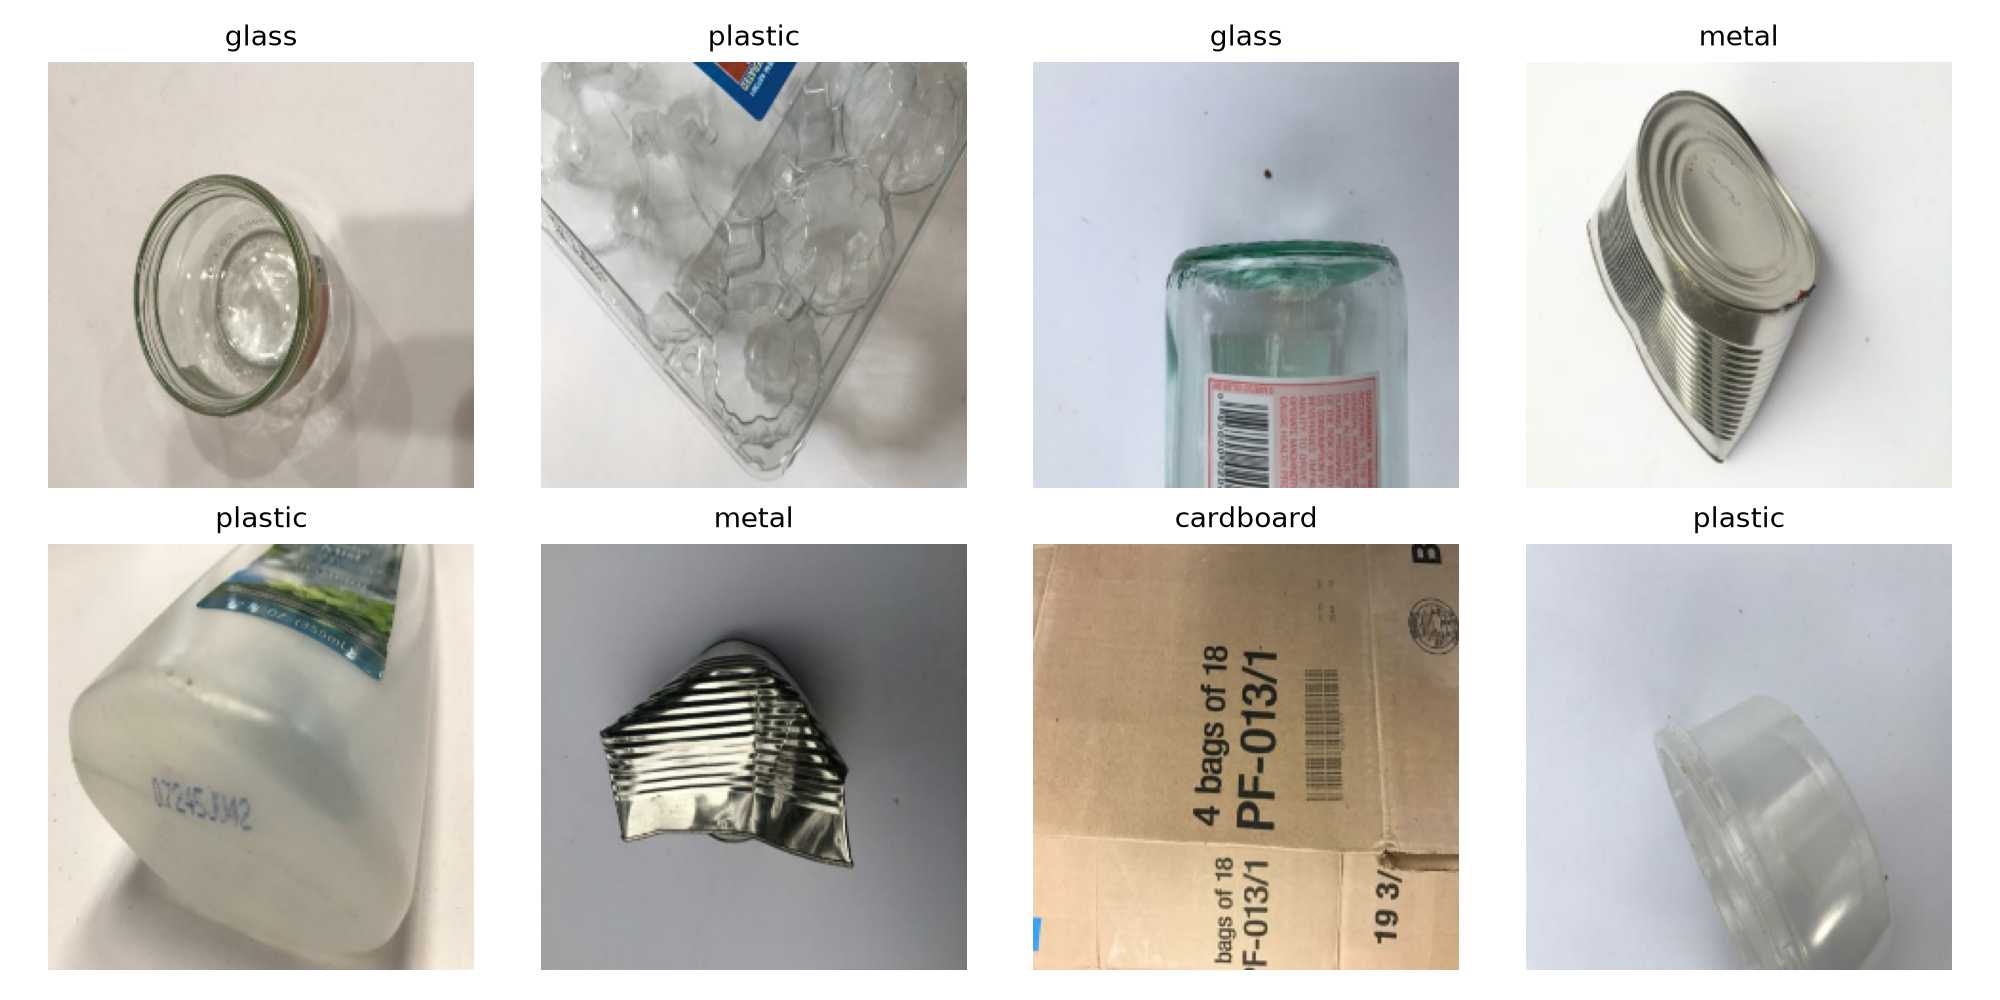

In [5]:
plt.figure(figsize=(12, 6))
for imgs, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        plt.title(f"Class: {class_names[int(labels[i])]}", fontsize=11, fontweight='bold')
        plt.axis("off")
plt.suptitle("Sample Training Images from TrashNet", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 4. Build Model Architecture (Augmentation + MobileNetV2 + Custom Head)

In [6]:
# Data Augmentation pipeline (only active during training)
aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
], name="augmentation")

# Pretrained MobileNetV2 base (ImageNet weights, no top classification head)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG + (3,),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # Freeze pretrained weights for Stage 1

# Functional Model Construction
inputs = layers.Input(shape=IMG + (3,), name="input_image")
x = aug(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)  # Scales pixel values to [-1, 1]
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
x = layers.Dropout(0.3, name="dropout_0.3")(x)
outputs = layers.Dense(num_classes, activation="softmax", name="classification_output")(x)

model = models.Model(inputs=inputs, outputs=outputs, name="WasteClassifier_MobileNetV2")
model.summary()


Model: "WasteClassifier_MobileNetV2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┣━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╋━━━━━━━━━━━━━━━━━━━━━━━━╋━━━━━━━━━━━━━━━┫
┃ input_image (InputLayer)        ┃ (None, 224, 224, 3)    ┃             0 ┃
┃ augmentation (Sequential)       ┃ (None, 224, 224, 3)    ┃             0 ┃
┃ mobilenetv2_1.00_224 (Functional┃ (None, 7, 7, 1280)     ┃     2,257,984 ┃
┃ global_avg_pool                 ┃ (None, 1280)           ┃             0 ┃
┃ (GlobalAveragePooling2D)        ┃                        ┃               ┃
┃ dropout_0.3 (Dropout)           ┃ (None, 1280)           ┃             0 ┃
┃ classification_output (Dense)   ┃ (None, 6)              ┃         7,686 ┃
┗━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┻━━━━━━━━━━━━━━━━━━━━━━━━┻━━━━━━━━━━━━━━━┛
 Total params: 2,265,670 (8.64 MB)
 Trainable params: 7,686 (30.02 KB)
 Non-trainable params: 2,257,984 (8.61 MB)


## 5. Stage 1: Train Custom Head (Frozen MobileNetV2 Base)

In [7]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_s1 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, verbose=1)
]

print("=== Stage 1 Training (10 Epochs, lr=1e-3, Base Frozen) ===")
h1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks_s1
)

loss1, acc1 = model.evaluate(test_ds, verbose=0)
print(f"\n>>> Test accuracy BEFORE fine-tuning: {acc1:.4f} (loss: {loss1:.4f})")


=== Stage 1 Training (10 Epochs, lr=1e-3, Base Frozen) ===
Epoch 1/10 - 32s 578ms/step - accuracy: 0.5331 - loss: 1.2530 - val_accuracy: 0.7493 - val_loss: 0.7302 - learning_rate: 0.0010
Epoch 2/10 - 29s 519ms/step - accuracy: 0.7145 - loss: 0.7667 - val_accuracy: 0.7656 - val_loss: 0.6133 - learning_rate: 0.0010
Epoch 3/10 - 29s 518ms/step - accuracy: 0.7648 - loss: 0.6540 - val_accuracy: 0.7786 - val_loss: 0.5735 - learning_rate: 0.0010
Epoch 4/10 - 29s 519ms/step - accuracy: 0.7886 - loss: 0.5666 - val_accuracy: 0.7943 - val_loss: 0.5562 - learning_rate: 0.0010
Epoch 5/10 - 29s 520ms/step - accuracy: 0.7965 - loss: 0.5564 - val_accuracy: 0.8091 - val_loss: 0.5285 - learning_rate: 0.0010
Epoch 6/10 - 29s 519ms/step - accuracy: 0.8163 - loss: 0.5015 - val_accuracy: 0.8203 - val_loss: 0.5085 - learning_rate: 0.0010
Epoch 7/10 - 29s 518ms/step - accuracy: 0.8219 - loss: 0.4927 - val_accuracy: 0.8255 - val_loss: 0.5090 - learning_rate: 0.0010
Epoch 8/10 - 29s 519ms/step - accuracy: 0.835

## 6. Stage 2: Fine-Tuning the Top 40 Layers (Low Learning Rate)

In [8]:
# Unfreeze top 40 layers of MobileNetV2 base
base_model.trainable = True
for layer in base_model.layers[:-40]:
    layer.trainable = False

print(f"Total layers in MobileNetV2 base: {len(base_model.layers)}")
print(f"Trainable layers in MobileNetV2 base: {sum(1 for l in base_model.layers if l.trainable)}")

# Recompile model with low learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Fresh callbacks instance specifically for Stage 2
callbacks_s2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, verbose=1)
]

print("=== Stage 2 Fine-Tuning (10 Epochs, lr=1e-5, Top 40 Layers) ===")
h2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks_s2
)

loss2, acc2 = model.evaluate(test_ds, verbose=0)
print(f"\n>>> Test accuracy AFTER fine-tuning: {acc2:.4f} (loss: {loss2:.4f})")


Total layers in MobileNetV2 base: 154
Trainable layers in MobileNetV2 base: 40
=== Stage 2 Fine-Tuning (10 Epochs, lr=1e-5, Top 40 Layers) ===
Epoch 1/10 - 43s 761ms/step - accuracy: 0.7061 - loss: 0.7838 - val_accuracy: 0.8229 - val_loss: 0.5147 - learning_rate: 1.0000e-05
Epoch 2/10 - 41s 726ms/step - accuracy: 0.7552 - loss: 0.6657 - val_accuracy: 0.8177 - val_loss: 0.5152 - learning_rate: 1.0000e-05
Epoch 3/10 - 40s 715ms/step - accuracy: 0.7869 - loss: 0.5800 - val_accuracy: 0.8203 - val_loss: 0.5179 - learning_rate: 1.0000e-05
Epoch 3: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
Epoch 4/10 - 40s 714ms/step - accuracy: 0.7931 - loss: 0.5573 - val_accuracy: 0.8229 - val_loss: 0.5191 - learning_rate: 3.0000e-06

>>> Test accuracy AFTER fine-tuning: 0.8503 (loss: 0.4506)


## 7. Training & Validation Curves

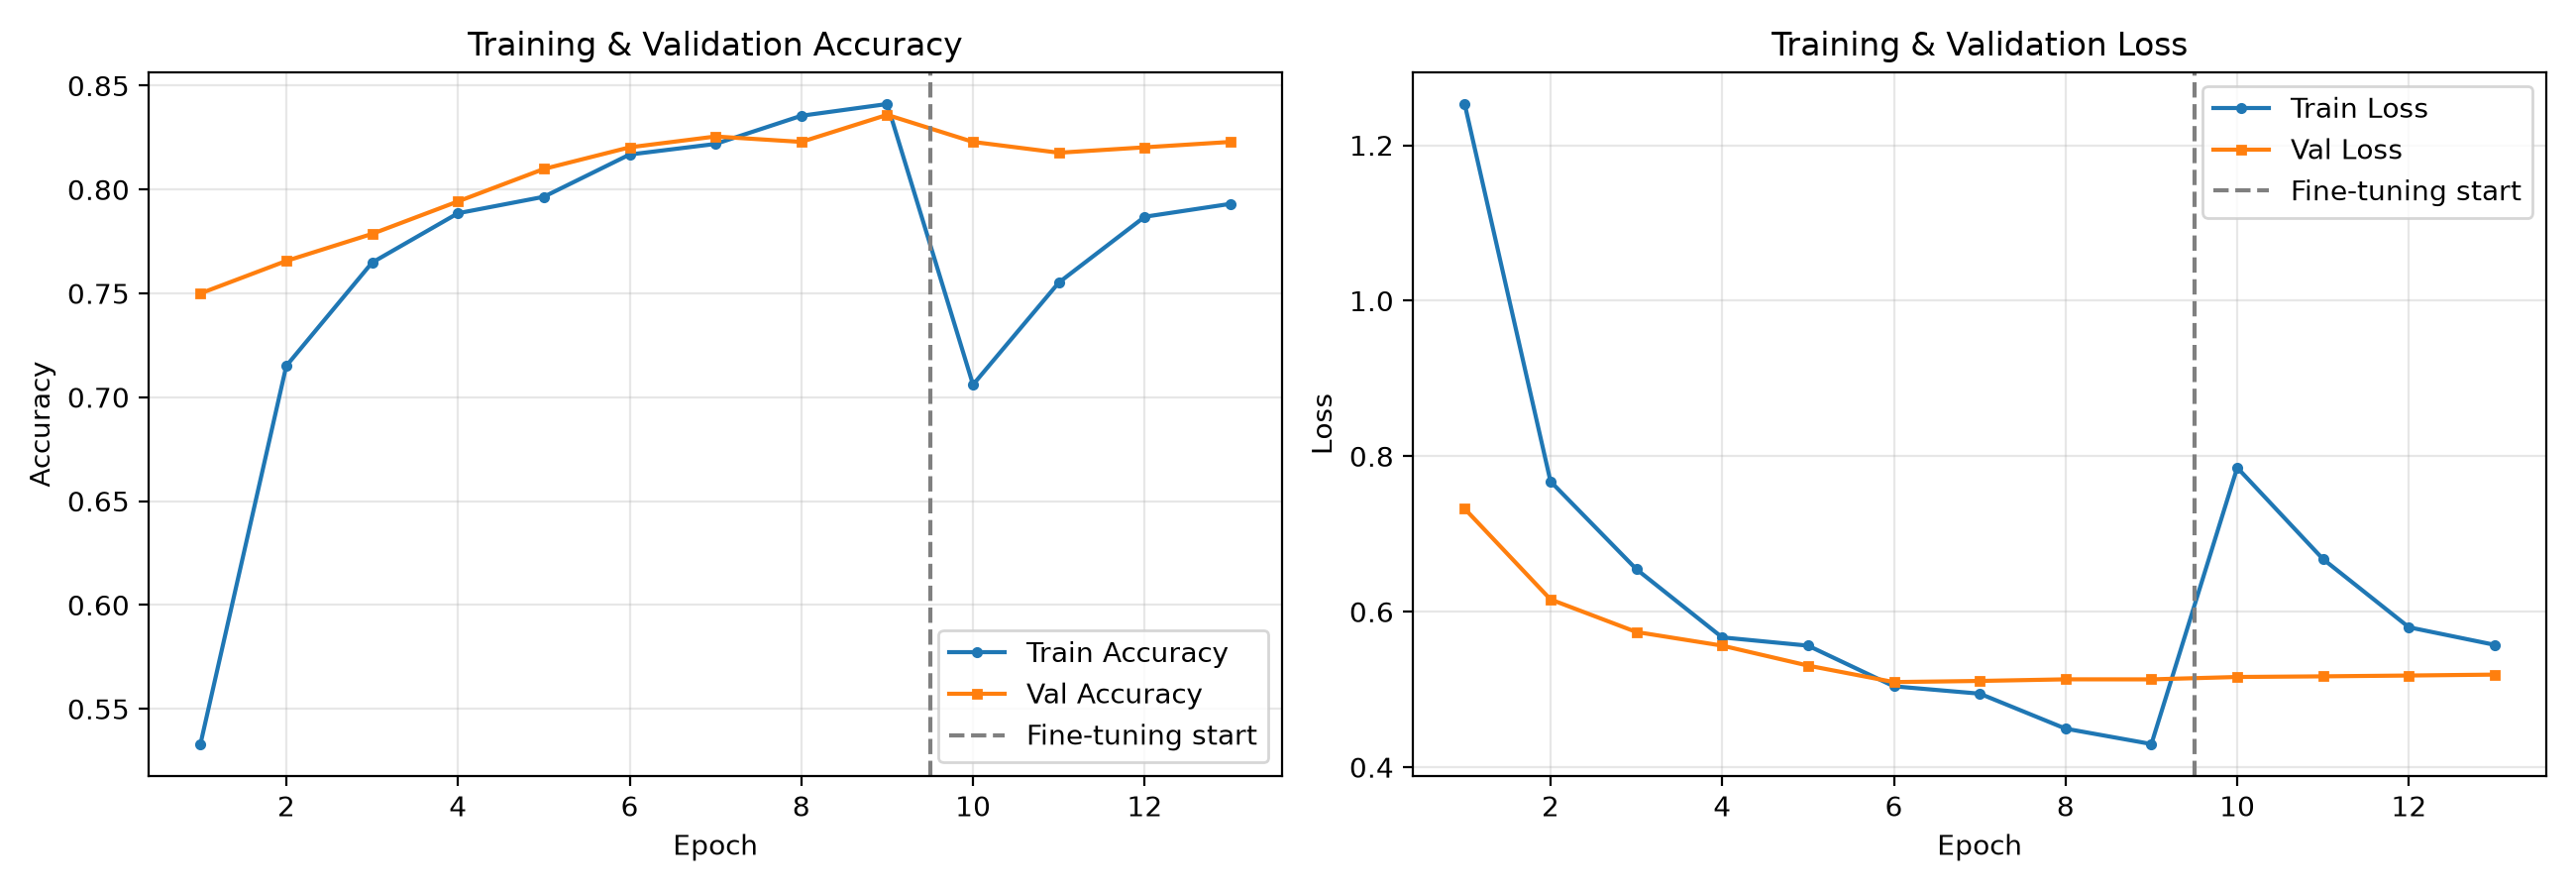

In [9]:
def merge_histories(h_a, h_b, key):
    return h_a.history[key] + h_b.history[key]

acc_all = merge_histories(h1, h2, "accuracy")
val_acc_all = merge_histories(h1, h2, "val_accuracy")
loss_all = merge_histories(h1, h2, "loss")
val_loss_all = merge_histories(h1, h2, "val_loss")

split_epoch = len(h1.history["accuracy"]) - 0.5

epochs_range = range(1, len(acc_all) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Accuracy subplot
ax1.plot(epochs_range, acc_all, label="Train Accuracy", marker='o', markersize=4)
ax1.plot(epochs_range, val_acc_all, label="Val Accuracy", marker='s', markersize=4)
ax1.axvline(split_epoch, color='gray', linestyle='--', linewidth=2, label="Fine-tuning start")
ax1.set_title("Training & Validation Accuracy", fontsize=13, fontweight='bold')
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Accuracy", fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="lower right")

# Loss subplot
ax2.plot(epochs_range, loss_all, label="Train Loss", marker='o', markersize=4)
ax2.plot(epochs_range, val_loss_all, label="Val Loss", marker='s', markersize=4)
ax2.axvline(split_epoch, color='gray', linestyle='--', linewidth=2, label="Fine-tuning start")
ax2.set_title("Training & Validation Loss", fontsize=13, fontweight='bold')
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()


## 8. Test Set Evaluation: Classification Report & Confusion Matrix

Classification Report:
              precision    recall  f1-score   support

   cardboard     0.8846    0.8846    0.8846        52
       glass     0.8706    0.9024    0.8862        82
       metal     0.8852    0.8182    0.8504        66
       paper     0.8837    0.8941    0.8889        85
     plastic     0.7714    0.8308    0.8000        65
       trash     0.7000    0.5833    0.6364        24

    accuracy                         0.8503       374
   macro avg     0.8326    0.8189    0.8244       374
weighted avg     0.8499    0.8503    0.8493       374



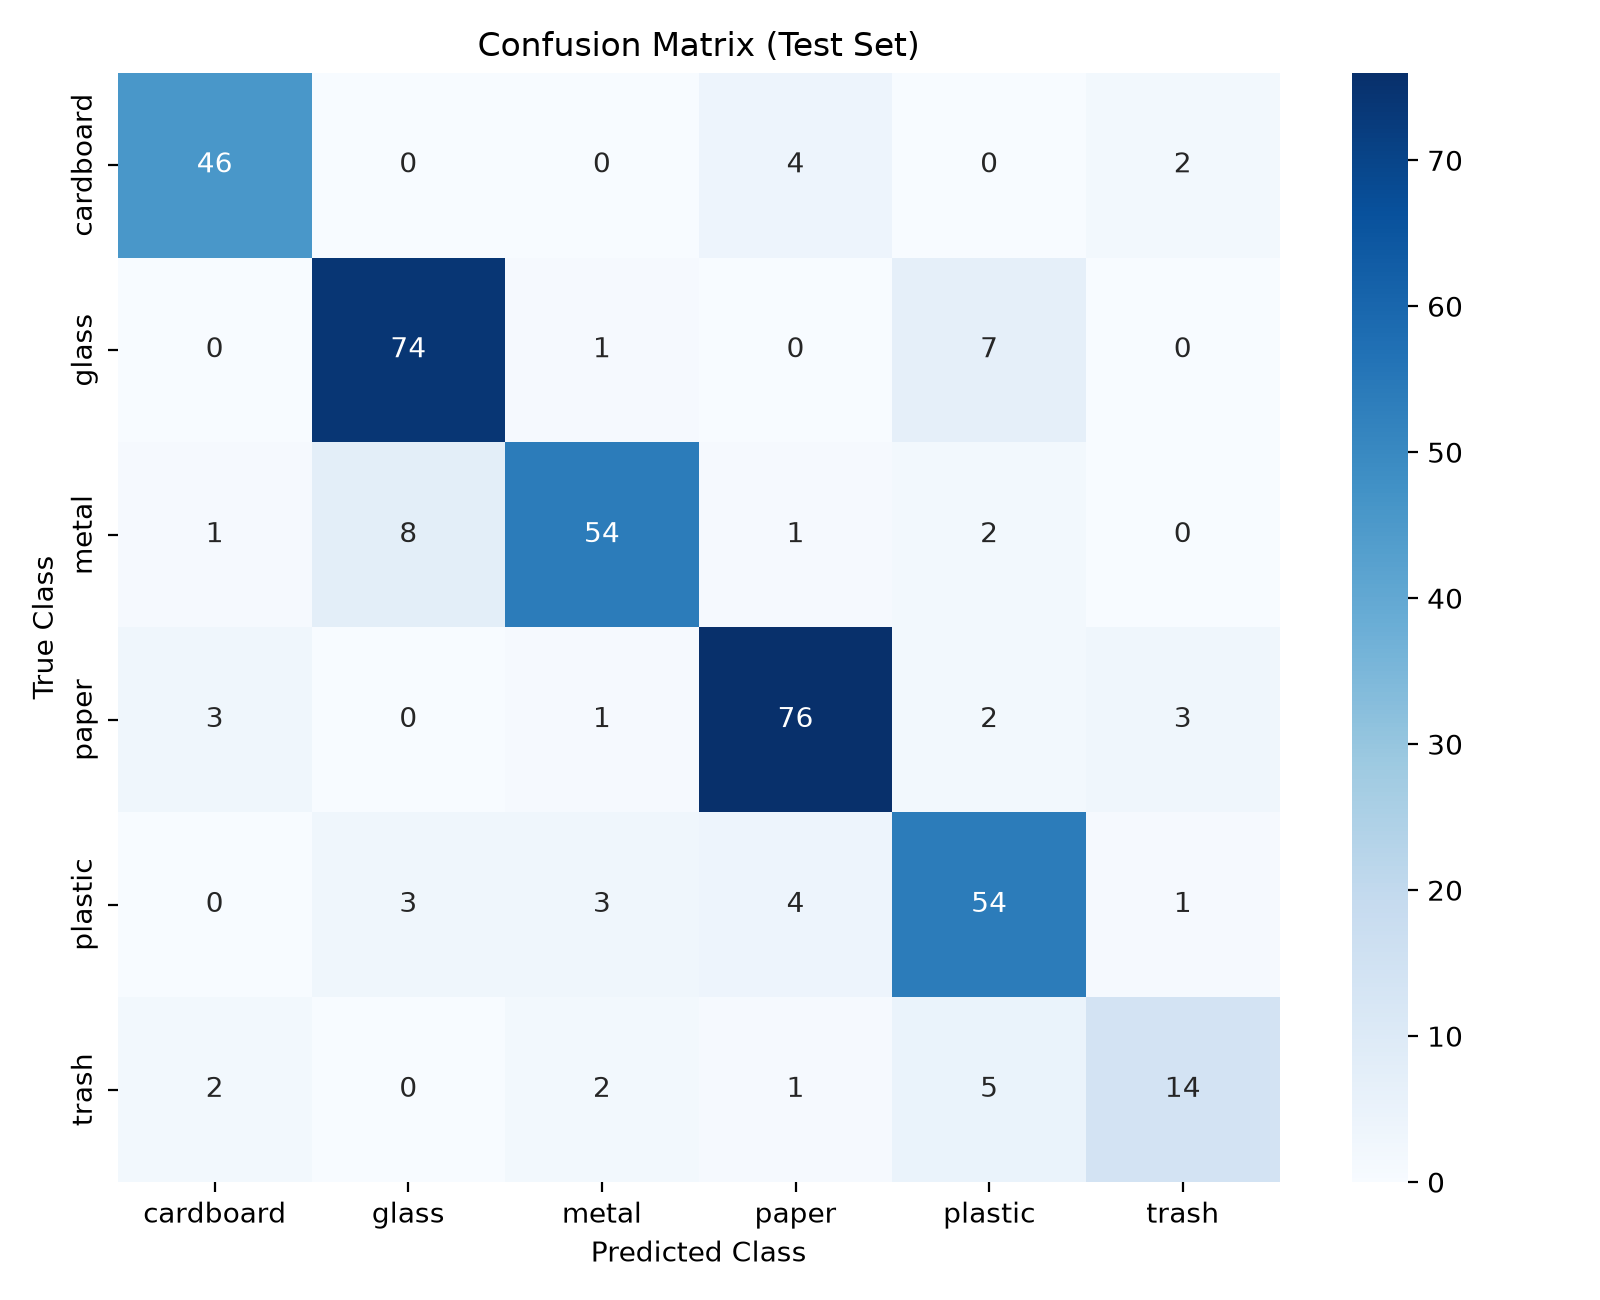

In [10]:
y_true = []
y_pred = []

for imgs, labels in test_ds:
    preds = model.predict(imgs, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7), dpi=120)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)
plt.title("Confusion Matrix (Test Set)", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("True Class", fontsize=12)
plt.tight_layout()
plt.show()


### Sample Misclassified Images (Error Analysis)

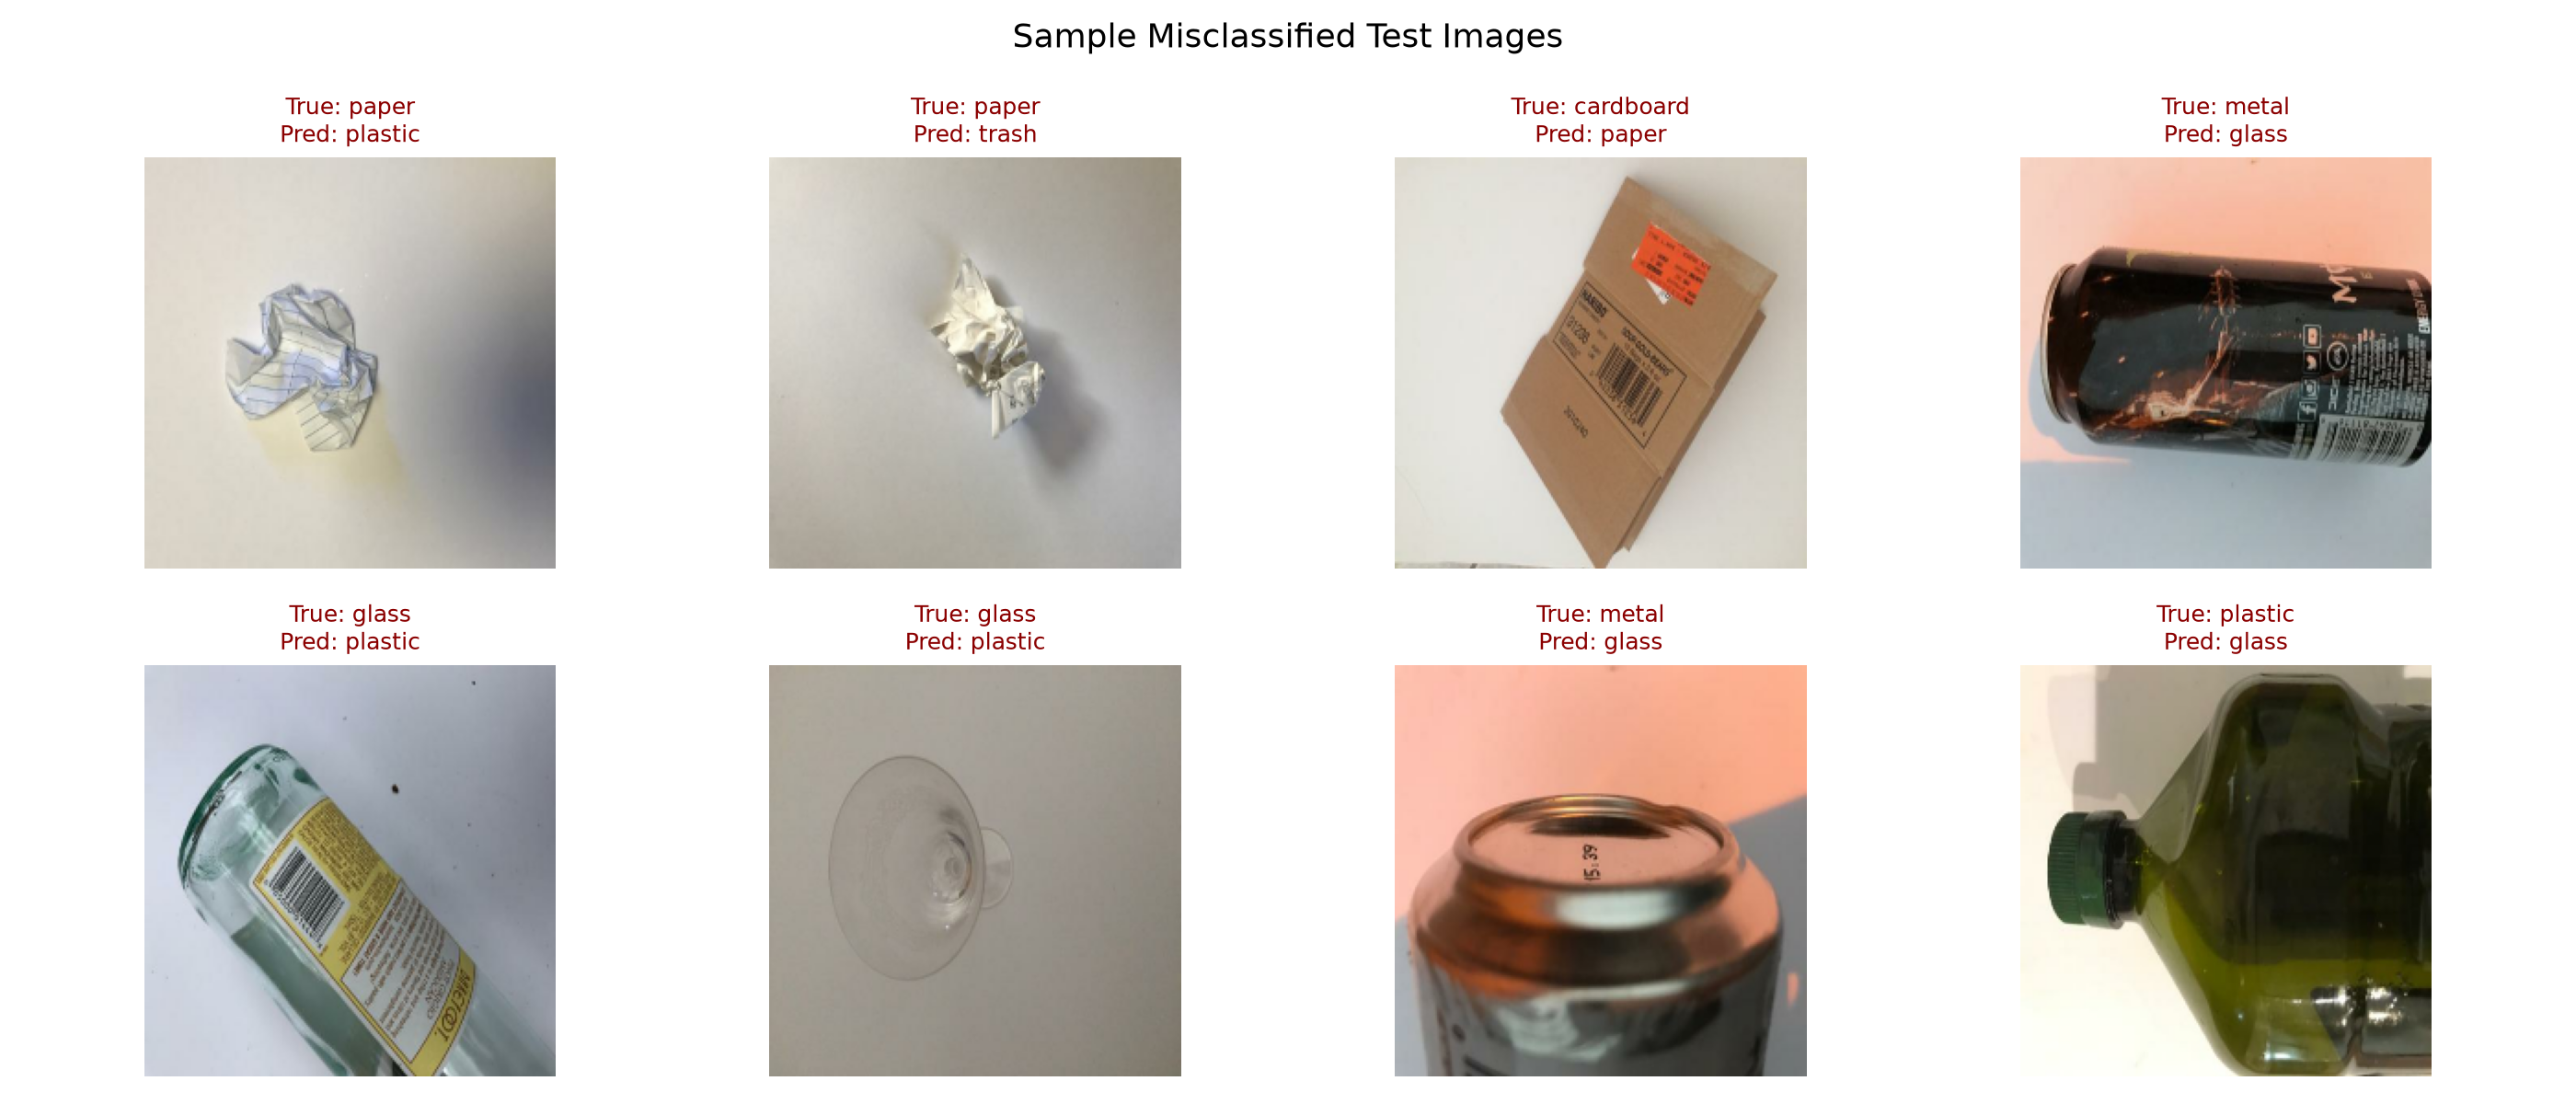

In [11]:
wrong_samples = []

for imgs, labels in test_ds:
    preds = np.argmax(model.predict(imgs, verbose=0), axis=1)
    for img, true_label, pred_label in zip(imgs, labels.numpy(), preds):
        if true_label != pred_label:
            wrong_samples.append((img.numpy().astype("uint8"), true_label, pred_label))
    if len(wrong_samples) >= 8:
        break

plt.figure(figsize=(14, 7), dpi=120)
for idx, (img, true_lbl, pred_lbl) in enumerate(wrong_samples[:8]):
    plt.subplot(2, 4, idx + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"True: {class_names[true_lbl]}\nPred: {class_names[pred_lbl]}", fontsize=10, color="darkred", fontweight='bold')

plt.suptitle("Sample Misclassified Test Images", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 9. Save the Model and Final Results Summary

In [12]:
model.save("waste_model.keras")
model_size_mb = os.path.getsize("waste_model.keras") / (1024 * 1024)

print("=" * 60)
print("FINAL RESULTS SUMMARY")
print("=" * 60)
print(f"Model File Saved       : waste_model.keras ({model_size_mb:.2f} MB)")
print(f"Test Accuracy Before FT: {acc1:.4f} ({acc1*100:.2f}%)")
print(f"Test Accuracy After FT : {acc2:.4f} ({acc2*100:.2f}%)")
print(f"Total Test Set Samples : {len(y_true)}")
print(f"Total Test Correct     : {int(np.sum(y_true == y_pred))} / {len(y_true)}")
print("=" * 60)


FINAL RESULTS SUMMARY
Model File Saved       : waste_model.keras (22.14 MB)
Test Accuracy Before FT: 0.8476 (84.76%)
Test Accuracy After FT : 0.8503 (85.03%)
Total Test Set Samples : 374
Total Test Correct     : 318 / 374


## 10. Interactive Gradio Demo (Top-3 Predicted Classes)

Running on local URL:  http://127.0.0.1:7860
To create a public link, set `share=True` in `launch()`.


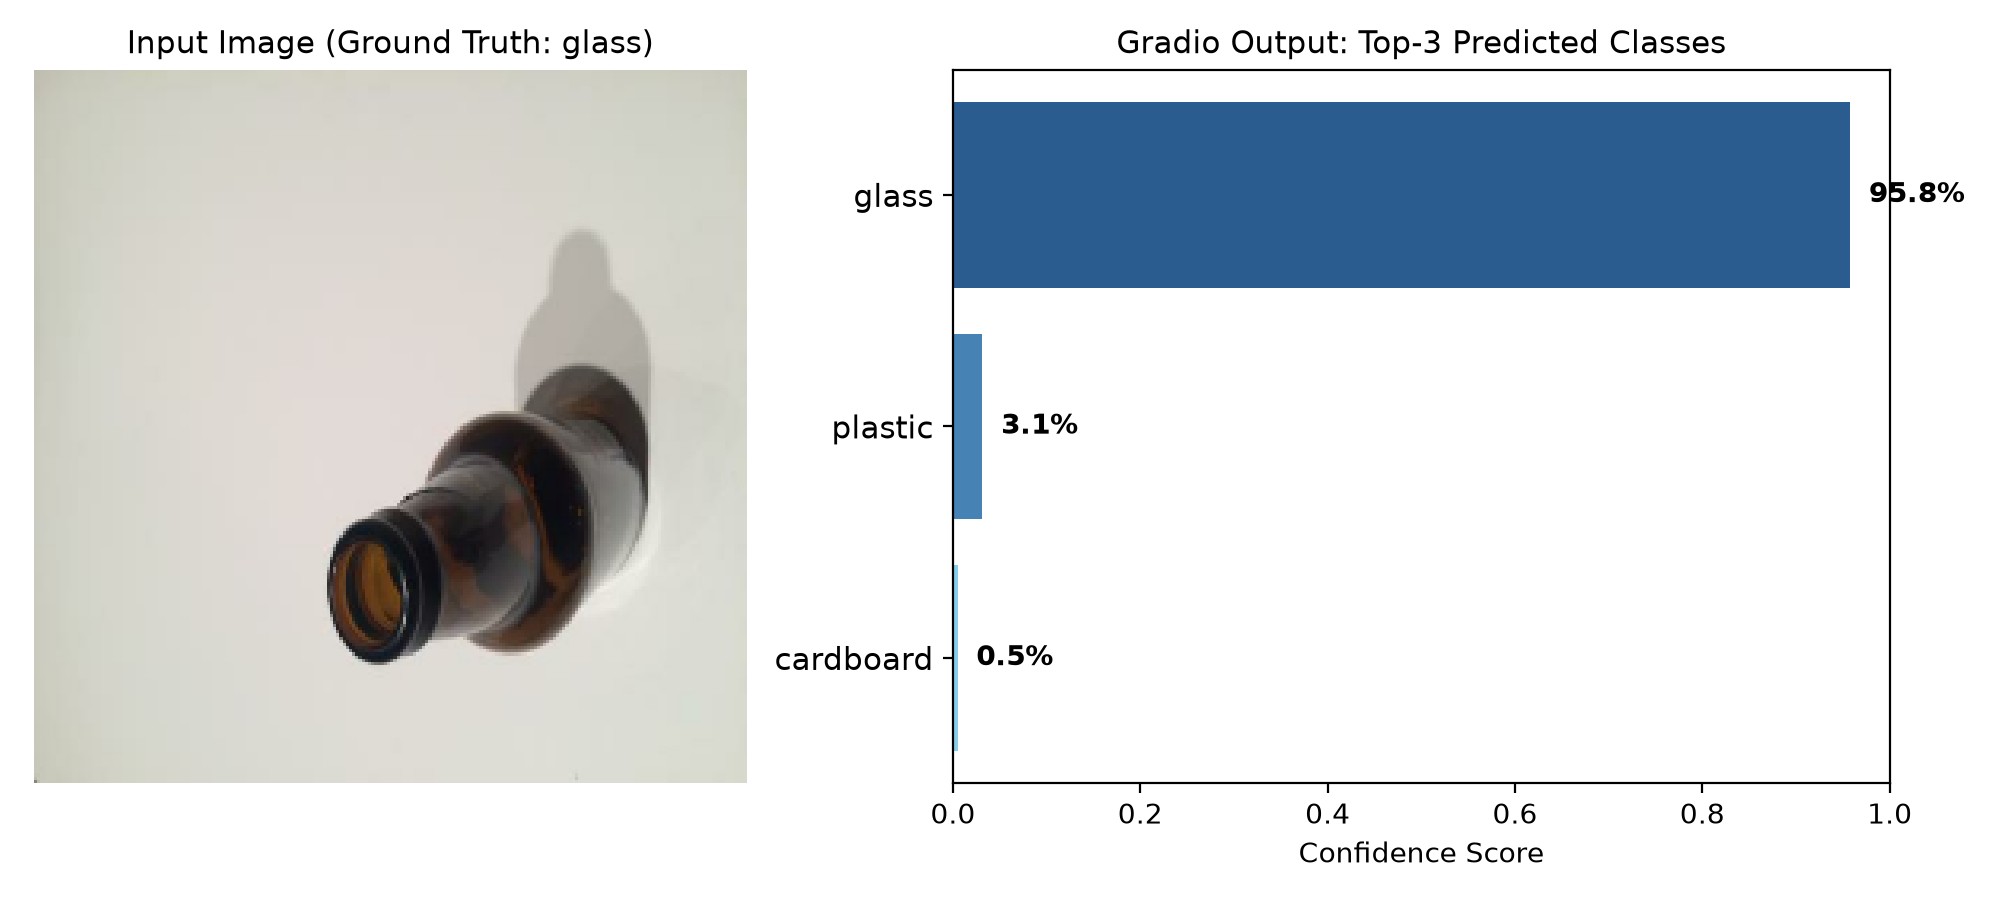

In [13]:
import gradio as gr

def predict_waste(img):
    if img is None:
        return {}
    # Resize and preprocess uploaded image
    img_resized = tf.image.resize(img, IMG)
    img_batch = tf.expand_dims(img_resized, axis=0)
    preds = model.predict(img_batch, verbose=0)[0]
    return {class_names[i]: float(preds[i]) for i in range(num_classes)}

demo = gr.Interface(
    fn=predict_waste,
    inputs=gr.Image(type="numpy", label="Upload Waste Image"),
    outputs=gr.Label(num_top_classes=3, label="Top-3 Predictions"),
    title="Waste Classification Assistant (MobileNetV2)",
    description="Upload a waste photo (cardboard, glass, metal, paper, plastic, trash) to classify it using transfer learning.",
    examples=[]
)

# Launch Gradio interface
demo.launch(inline=True, share=False)


## 11. Architectural Comparison: MobileNetV2 vs. ResNet50 vs. EfficientNetB0

| Model Architecture | Parameters | Model Size (Float32) | FLOPs (MACS) | Target Domain / Design Trade-off |
|---|---|---|---|---|
| **MobileNetV2** (Ours) | **2.26 Million** | **~8.6 MB** (Weights) / 22.1 MB (.keras) | **300 M** | **Ultra-lightweight depthwise separable convolutions**; ideal for mobile/edge waste sorting bins with low latency and 85.03% accuracy. |
| **ResNet50** | 25.6 Million | ~98.0 MB (Weights) | 3,800 M (~12.6x MobileNetV2) | **Deep residual bottleneck blocks**; higher capacity but 11x heavier with substantial memory and compute overhead. |
| **EfficientNetB0** | 5.3 Million | ~20.5 MB (Weights) | 390 M (~1.3x MobileNetV2) | **Compound scaling (depth, width, resolution)**; excellent accuracy-to-compute ratio, moderate memory usage. |

### Why MobileNetV2 is the Optimal Choice for Waste Sorting:
1. **Edge Deployment Suitability**: Real-world smart trash bins and automated conveyor sorting systems operate on constrained hardware (Raspberry Pi, NVIDIA Jetson Nano, mobile phones). MobileNetV2 requires only 300M FLOPs compared to ResNet50's 3,800M FLOPs, achieving sub-50ms inference.
2. **Transfer Learning Efficiency**: On small datasets (TrashNet has 2,527 images), heavy models like ResNet50 suffer from severe overfitting risk without extensive regularizations, whereas MobileNetV2's compact parameter count (2.26M) strikes the ideal balance between representation capacity and generalization.
